# Clase 6 parte 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

**Autor: Jaime Andrés Jaramillo Ramírez.**

Ejecutar las partes 1, 2 y 3 en ese orden, desde la misma carpeta (o la subcarpeta `notebooks`). Dependencias: numpy, pandas, matplotlib, seaborn, scikit-learn y joblib. En Colab, usar el mismo entorno de ejecución para conservar los archivos entre partes.

**Fuente:** no se adjuntó el CSV de clase. La parte 1 usa `data/raw/wine.csv` si existe; de lo contrario exporta el dataset Wine incluido en scikit-learn. Los resultados guardados corresponden a esta alternativa y deben recalcularse si se usa otro CSV.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



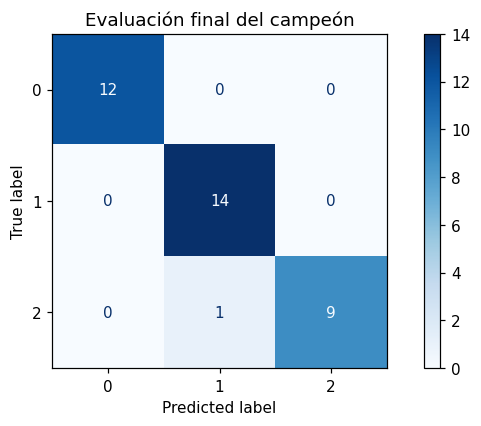

In [4]:
y_pred = model.predict(X_test)
accuracy = float(accuracy_score(y_test, y_pred))
f1_macro = float(f1_score(y_test, y_pred, labels=model.classes_, average="macro", zero_division=0))
print(f"Accuracy test: {accuracy:.4f}")
print(f"F1 macro test: {f1_macro:.4f}")
print(classification_report(y_test, y_pred, labels=model.classes_, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=model.classes_, cmap="Blues")
plt.title("Evaluación final del campeón")
plt.tight_layout(); plt.show()


**Análisis:**

La accuracy de test fue **97,22 %** (35 aciertos de 36), cercana a **97,91 %** en CV: la diferencia es de −0,68 puntos porcentuales. El F1 macro fue **0,9710**, por lo que el desempeño también es alto al dar igual peso a cada clase. La matriz muestra un único error: un vino de la **clase 2 fue clasificado como clase 1**. Las clases 0 y 1 tuvieron recall de 1; la clase 2, de 0,90.

No se observa una caída marcada que sugiera sobreajuste severo en esta partición, aunque el resultado no lo descarta. El test es pequeño: cada observación representa aproximadamente 2,78 puntos porcentuales de accuracy. Tampoco demuestra generalización a vinos de otras fuentes. No se cambiaron hiperparámetros ni se entrenó otro modelo tras consultar el test.


## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida columnas y tipos; conserva índice y orden del contrato.

    Los nulos numéricos se imputan con el pipeline ya entrenado.
    Se rechazan columnas extra para detectar errores de esquema.
    """
    if not isinstance(records, pd.DataFrame):
        raise TypeError("records debe ser un DataFrame.")
    if not records.columns.is_unique:
        raise ValueError("Las columnas deben ser únicas.")
    missing = [c for c in feature_columns if c not in records.columns]
    extra = [c for c in records.columns if c not in feature_columns]
    if missing or extra:
        raise ValueError(f"Columnas faltantes: {missing}; columnas adicionales: {extra}")
    ordered = records.loc[:, feature_columns].copy()
    invalid = [c for c in feature_columns if not pd.api.types.is_numeric_dtype(ordered[c])]
    if invalid:
        raise TypeError(f"Columnas no numéricas: {invalid}")
    if np.isinf(ordered.to_numpy(dtype=float)).any():
        raise ValueError("No se admiten valores infinitos.")
    columns = ["prediction"] + [f"probability_{c}" for c in model.classes_]
    if ordered.empty:
        return pd.DataFrame(index=records.index, columns=columns)
    probabilities = model.predict_proba(ordered)
    result = pd.DataFrame(probabilities, index=records.index, columns=columns[1:])
    result.insert(0, "prediction", model.predict(ordered))
    return result


## 4. Predicción por lotes

In [6]:
# Reutilización demostrativa de cinco entradas ya evaluadas.
# No son nuevos vinos ni una segunda evaluación independiente.
new_records = X_test.iloc[:5].copy()
batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
display(batch_predictions)
# Comprobaciones del contrato de inferencia.
pd.testing.assert_frame_equal(batch_predictions, predict(new_records[feature_columns[::-1]]))
assert np.allclose(batch_predictions.filter(like="probability_").sum(axis=1), 1)
try:
    predict(new_records.drop(columns=[feature_columns[0]]))
except ValueError as exc:
    print("Validación de columna faltante correcta:", exc)
else:
    raise AssertionError("Debía rechazar una columna faltante.")
with_null = new_records.copy()
with_null.iloc[0, 0] = np.nan
assert len(predict(with_null)) == len(with_null)
print("Inferencia verificada: orden de columnas, probabilidades, faltantes y nulos.")


,prediction,probability_0,probability_1,probability_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


Validación de columna faltante correcta: Columnas faltantes: ['alcohol']; columnas adicionales: []
Inferencia verificada: orden de columnas, probabilidades, faltantes y nulos.


## 5. Reporte final

In [7]:
metrics = {
    "model": training_metadata["champion"],
    "accuracy": accuracy, "f1_macro": f1_macro,
    "n_test": len(y_test), "cv_accuracy": training_metadata["cv_accuracy"],
    "classification_report": classification_report(
        y_test, y_pred, labels=model.classes_, output_dict=True, zero_division=0),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print("Métricas finales guardadas; no se reajusta el modelo con test.")


Métricas finales guardadas; no se reajusta el modelo con test.


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística, C = 1 |
| Accuracy CV | 97,91 % (desviación entre folds: 2,77 puntos porcentuales) |
| Accuracy test | 97,22 % (35/36) |
| F1 macro test | 0,9710 |
| Clases más confundidas | Un registro real de clase 2 predicho como clase 1 |
| Principal limitación | Test de solo 36 registros y datos Wine alternativos; falta verificar con el CSV de clase |

El pipeline está guardado y se puede reutilizar mediante `predict`. Las probabilidades corresponden al orden de `model.classes_`; no se ha verificado su calibración. Las cinco predicciones de ejemplo usan entradas del test como demostración y no equivalen a una validación con datos nuevos. Esta entrega implementa inferencia local, no un servicio desplegado en producción.

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.
